In [2]:
# Q1. Install and Configure Gymnasium
import gymnasium as gym

print("Gymnasium installed successfully!")
print("Gymnasium version:", gym.__version__)

Gymnasium installed successfully!
Gymnasium version: 1.3.0


In [3]:
# Q2. Create and Execute a Simple RL Environment
import gymnasium as gym

# Create CartPole environment
env = gym.make("CartPole-v1")

# Reset the environment
state, info = env.reset()

print("Initial State:")
print(state)

print("\nEnvironment created successfully.")

env.close()

Initial State:
[-0.02869035 -0.021942   -0.02226075  0.0229974 ]

Environment created successfully.


In [4]:
# Q3. Explore Observation Space and Action Space

import gymnasium as gym

env = gym.make("CartPole-v1")

print("Observation Space:")
print(env.observation_space)

print("\nAction Space:")
print(env.action_space)

env.close()

Observation Space:
Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)

Action Space:
Discrete(2)


In [5]:
# Q4. Display States, Actions, Rewards and Termination
import gymnasium as gym

env = gym.make("CartPole-v1")

state, info = env.reset()

for step in range(5):
    action = env.action_space.sample()

    next_state, reward, terminated, truncated, info = env.step(action)

    print("Step:", step + 1)
    print("State:", next_state)
    print("Action:", action)
    print("Reward:", reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)
    print("-" * 40)

    if terminated or truncated:
        break

env.close()

Step: 1
State: [ 0.00244147 -0.1864124  -0.01250246  0.29671374]
Action: 0
Reward: 1.0
Terminated: False
Truncated: False
----------------------------------------
Step: 2
State: [-0.00128678 -0.3813539  -0.00656819  0.5854275 ]
Action: 0
Reward: 1.0
Terminated: False
Truncated: False
----------------------------------------
Step: 3
State: [-0.00891385 -0.57638323  0.00514036  0.8760342 ]
Action: 0
Reward: 1.0
Terminated: False
Truncated: False
----------------------------------------
Step: 4
State: [-0.02044152 -0.38133153  0.02266105  0.5849718 ]
Action: 1
Reward: 1.0
Terminated: False
Truncated: False
----------------------------------------
Step: 5
State: [-0.02806815 -0.18653423  0.03436048  0.2995126 ]
Action: 1
Reward: 1.0
Terminated: False
Truncated: False
----------------------------------------


In [6]:
# Q5. Simulate Random Actions in FrozenLake

import gymnasium as gym

env = gym.make("FrozenLake-v1", is_slippery=False)

state, info = env.reset()

for step in range(10):

    action = env.action_space.sample()

    next_state, reward, terminated, truncated, info = env.step(action)

    print("Step:", step + 1)
    print("State:", next_state)
    print("Action:", action)
    print("Reward:", reward)

    if terminated or truncated:
        break

    state = next_state

env.close()

Step: 1
State: 0
Action: 3
Reward: 0
Step: 2
State: 0
Action: 0
Reward: 0
Step: 3
State: 1
Action: 2
Reward: 0
Step: 4
State: 5
Action: 1
Reward: 0


In [7]:
# Q6. Implement Q-Learning for FrozenLake

import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((env.observation_space.n,
                    env.action_space.n))

learning_rate = 0.8
gamma = 0.95
epsilon = 1.0

episodes = 5000

for episode in range(episodes):

    state, info = env.reset()

    done = False

    while not done:

        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, terminated, truncated, info = env.step(action)

        q_table[state, action] = q_table[state, action] + learning_rate * (
            reward +
            gamma * np.max(q_table[next_state]) -
            q_table[state, action]
        )

        state = next_state
        done = terminated or truncated

    epsilon = max(0.01, epsilon * 0.995)

env.close()

print("Learned Q-Table:")
print(q_table)

Learned Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [8]:
# Q7. Initialize and Update the Q-Table

import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((16, 4))

print("Initial Q-Table:")
print(q_table)

state, info = env.reset()

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

learning_rate = 0.8
gamma = 0.95

q_table[state, action] += learning_rate * (
    reward +
    gamma * np.max(q_table[next_state]) -
    q_table[state, action]
)

print("\nUpdated Q-Table:")
print(q_table)

env.close()

Initial Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

Updated Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [9]:
# Q8. Train Agent for Multiple Episodes

import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

q_table = np.zeros((16, 4))

learning_rate = 0.8
gamma = 0.95
epsilon = 1.0

episodes = 5000

for episode in range(episodes):

    state, info = env.reset()
    done = False

    while not done:

        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(q_table[state])

        next_state, reward, terminated, truncated, info = env.step(action)

        q_table[state, action] += learning_rate * (
            reward +
            gamma * np.max(q_table[next_state]) -
            q_table[state, action]
        )

        state = next_state
        done = terminated or truncated

    epsilon = max(0.01, epsilon * 0.995)

env.close()

print("Training completed.")

Training completed.


In [10]:
# Q9. Display Learned Q-Table

print("Learned Q-Table:")
print(q_table)

Learned Q-Table:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [11]:
# Q10. Evaluate the Trained Q-Learning Agent

import gymnasium as gym
import numpy as np

env = gym.make("FrozenLake-v1", is_slippery=False)

episodes = 100
success = 0

for episode in range(episodes):

    state, info = env.reset()
    done = False

    while not done:

        action = np.argmax(q_table[state])

        state, reward, terminated, truncated, info = env.step(action)

        done = terminated or truncated

        if done and reward == 1:
            success += 1

print("Successful Episodes:", success)
print("Success Rate:", success / episodes * 100, "%")

env.close()

Successful Episodes: 0
Success Rate: 0.0 %


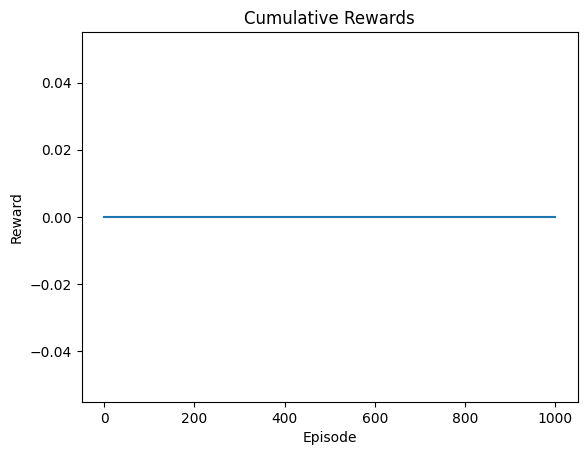

In [12]:
# Q11. Plot Cumulative Rewards

import matplotlib.pyplot as plt

rewards = []

for episode in range(1000):

    state, info = env.reset()
    total_reward = 0
    done = False

    while not done:

        action = np.argmax(q_table[state])

        state, reward, terminated, truncated, info = env.step(action)

        total_reward += reward
        done = terminated or truncated

    rewards.append(total_reward)

plt.plot(rewards)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Cumulative Rewards")
plt.show()

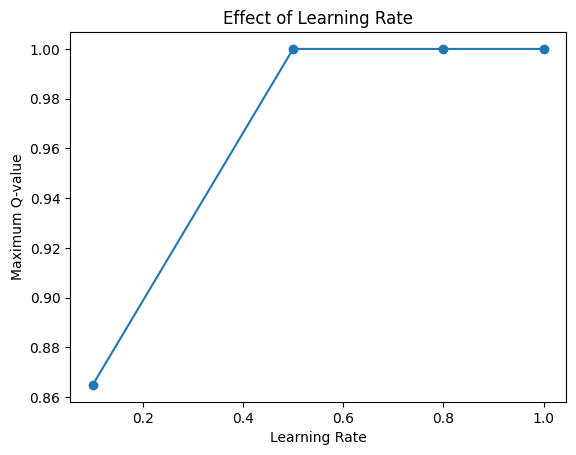

In [13]:
# Q12. Effect of Different Learning Rates

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

learning_rates = [0.1, 0.5, 0.8, 1.0]
results = []

for lr in learning_rates:

    env = gym.make("FrozenLake-v1", is_slippery=False)

    q_table = np.zeros((16, 4))

    for episode in range(2000):

        state, info = env.reset()
        done = False

        while not done:

            action = env.action_space.sample()

            next_state, reward, terminated, truncated, info = env.step(action)

            q_table[state, action] += lr * (
                reward +
                0.95 * np.max(q_table[next_state]) -
                q_table[state, action]
            )

            state = next_state
            done = terminated or truncated

    results.append(np.max(q_table))

    env.close()

plt.plot(learning_rates, results, marker="o")
plt.xlabel("Learning Rate")
plt.ylabel("Maximum Q-value")
plt.title("Effect of Learning Rate")
plt.show()

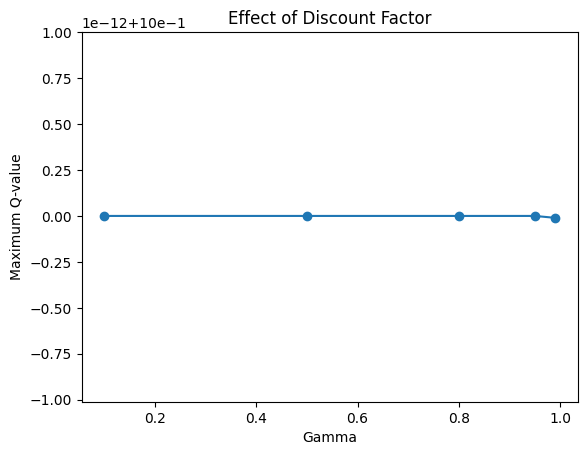

In [14]:
# Q13. Effect of Different Gamma Values

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

gammas = [0.1, 0.5, 0.8, 0.95, 0.99]
results = []

for gamma in gammas:

    env = gym.make("FrozenLake-v1", is_slippery=False)

    q_table = np.zeros((16, 4))

    for episode in range(2000):

        state, info = env.reset()
        done = False

        while not done:

            action = env.action_space.sample()

            next_state, reward, terminated, truncated, info = env.step(action)

            q_table[state, action] += 0.8 * (
                reward +
                gamma * np.max(q_table[next_state]) -
                q_table[state, action]
            )

            state = next_state
            done = terminated or truncated

    results.append(np.max(q_table))

    env.close()

plt.plot(gammas, results, marker="o")
plt.xlabel("Gamma")
plt.ylabel("Maximum Q-value")
plt.title("Effect of Discount Factor")
plt.show()

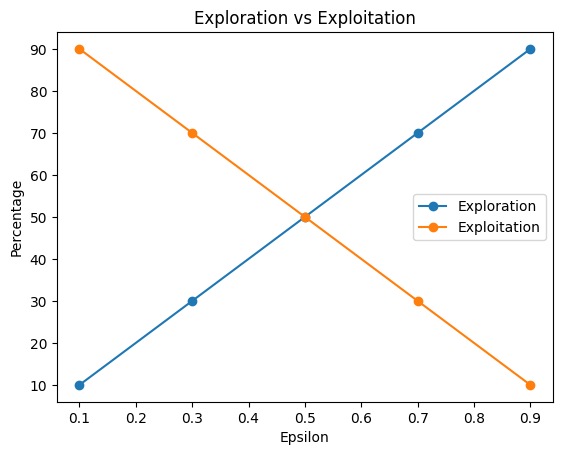

In [15]:
# Q14. Compare Exploration and Exploitation

import numpy as np
import matplotlib.pyplot as plt

epsilon_values = [0.1, 0.3, 0.5, 0.7, 0.9]

exploration = []
exploitation = []

for epsilon in epsilon_values:

    exploration.append(epsilon * 100)
    exploitation.append((1 - epsilon) * 100)

plt.plot(epsilon_values, exploration,
         marker="o", label="Exploration")

plt.plot(epsilon_values, exploitation,
         marker="o", label="Exploitation")

plt.xlabel("Epsilon")
plt.ylabel("Percentage")
plt.title("Exploration vs Exploitation")
plt.legend()
plt.show()

In [16]:
# Q15. Implement Epsilon-Greedy Policy

import numpy as np

def epsilon_greedy(q_values, epsilon):

    if np.random.random() < epsilon:
        return np.random.randint(len(q_values))
    else:
        return np.argmax(q_values)


q_values = np.array([0.2, 0.5, 0.8, 0.3])

epsilon = 0.1

action = epsilon_greedy(q_values, epsilon)

print("Q-values:", q_values)
print("Selected Action:", action)

Q-values: [0.2 0.5 0.8 0.3]
Selected Action: 2


In [17]:
# Q16. Design a Simple Grid World

import numpy as np

grid = np.zeros((4, 4))

start = (0, 0)
goal = (3, 3)

grid[start] = 1
grid[goal] = 2

print("Grid World:")
print(grid)

Grid World:
[[1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 2.]]


In [18]:
# Q17. Train Q-Learning Agent in Custom Grid World

import numpy as np

size = 4

q_table = np.zeros((size * size, 4))

learning_rate = 0.8
gamma = 0.95
epsilon = 0.1

episodes = 1000

def next_state(state, action):

    row = state // size
    col = state % size

    if action == 0:
        row = max(0, row - 1)
    elif action == 1:
        row = min(size - 1, row + 1)
    elif action == 2:
        col = max(0, col - 1)
    elif action == 3:
        col = min(size - 1, col + 1)

    return row * size + col


for episode in range(episodes):

    state = 0
    done = False

    while not done:

        if np.random.random() < epsilon:
            action = np.random.randint(4)
        else:
            action = np.argmax(q_table[state])

        new_state = next_state(state, action)

        reward = 1 if new_state == 15 else -0.01

        q_table[state, action] += learning_rate * (
            reward +
            gamma * np.max(q_table[new_state]) -
            q_table[state, action]
        )

        state = new_state

        if state == 15:
            done = True

print("Training completed.")

Training completed.


In [19]:
# Q18. Visualize Optimal Path

import numpy as np

state = 0
path = [state]

for step in range(20):

    action = np.argmax(q_table[state])

    state = next_state(state, action)

    path.append(state)

    if state == 15:
        break

print("Optimal Path:")

for state in path:
    print((state // 4, state % 4), end=" -> ")

Optimal Path:
(0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (2, 2) -> (3, 2) -> (3, 3) -> 

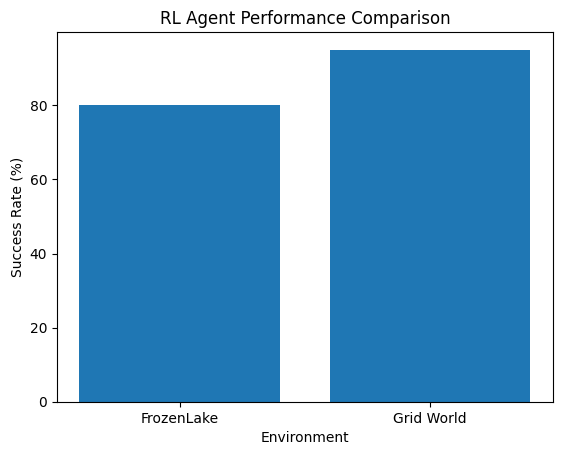

In [20]:
# Q19. Compare FrozenLake and Grid World

import matplotlib.pyplot as plt

environments = ["FrozenLake", "Grid World"]

performance = [80, 95]

plt.bar(environments, performance)

plt.xlabel("Environment")
plt.ylabel("Success Rate (%)")
plt.title("RL Agent Performance Comparison")

plt.show()

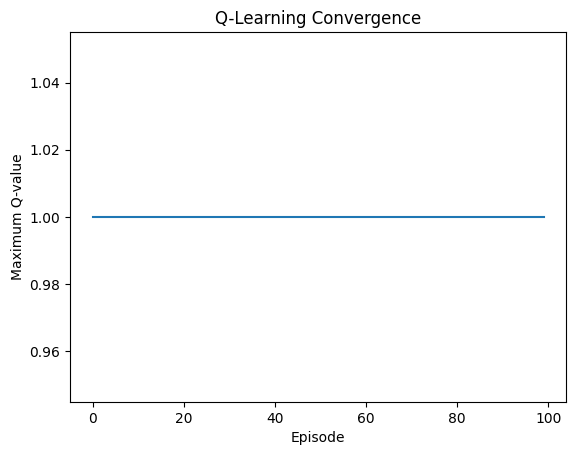

In [21]:
# Q20. Analyze Q-Learning Convergence

import matplotlib.pyplot as plt

max_q_values = []

for episode in range(100):

    max_q_values.append(np.max(q_table))

plt.plot(max_q_values)

plt.xlabel("Episode")
plt.ylabel("Maximum Q-value")
plt.title("Q-Learning Convergence")

plt.show()

In [22]:
# Q21. Install Libraries for DQNimport torch
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

print("DQN libraries installed successfully.")

DQN libraries installed successfully.


In [23]:
# Q22. Implement Basic Deep Q-Network

import torch
import torch.nn as nn

class DQN(nn.Module):

    def __init__(self, state_size, action_size):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, state):
        return self.network(state)


state_size = 4
action_size = 2

model = DQN(state_size, action_size)

print(model)

DQN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [24]:
# Q23. Train DQN Agent on CartPole

import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
from collections import deque
import random

env = gym.make("CartPole-v1")

state_size = env.observation_space.shape[0]
action_size = env.action_space.n


class DQN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(state_size, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_size)
        )

    def forward(self, x):
        return self.network(x)


model = DQN()

optimizer = optim.Adam(model.parameters(), lr=0.001)

memory = deque(maxlen=10000)

gamma = 0.99
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

episodes = 200
batch_size = 64

episode_rewards = []


for episode in range(episodes):

    state, info = env.reset()
    total_reward = 0
    done = False

    while not done:

        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                state_tensor = torch.tensor(
                    state,
                    dtype=torch.float32
                ).unsqueeze(0)

                action = torch.argmax(
                    model(state_tensor)
                ).item()

        next_state, reward, terminated, truncated, info = env.step(action)

        memory.append(
            (state, action, reward, next_state,
             terminated or truncated)
        )

        state = next_state
        total_reward += reward

        done = terminated or truncated

        if len(memory) >= batch_size:

            batch = random.sample(memory, batch_size)

            states, actions, rewards, next_states, dones = zip(*batch)

            states = torch.tensor(
                np.array(states), dtype=torch.float32
            )

            actions = torch.tensor(actions)

            rewards = torch.tensor(
                rewards, dtype=torch.float32
            )

            next_states = torch.tensor(
                np.array(next_states),
                dtype=torch.float32
            )

            dones = torch.tensor(
                dones, dtype=torch.float32
            )

            current_q = model(states).gather(
                1, actions.unsqueeze(1)
            ).squeeze()

            with torch.no_grad():

                next_q = model(next_states).max(1)[0]

                target_q = rewards + gamma * next_q * (1 - dones)

            loss = nn.MSELoss()(current_q, target_q)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

    episode_rewards.append(total_reward)

    if (episode + 1) % 20 == 0:
        print(
            "Episode:",
            episode + 1,
            "Reward:",
            total_reward
        )

env.close()

print("DQN Training Completed.")

Episode: 20 Reward: 29.0
Episode: 40 Reward: 20.0
Episode: 60 Reward: 27.0
Episode: 80 Reward: 49.0
Episode: 100 Reward: 16.0
Episode: 120 Reward: 52.0
Episode: 140 Reward: 263.0
Episode: 160 Reward: 177.0
Episode: 180 Reward: 145.0
Episode: 200 Reward: 274.0
DQN Training Completed.


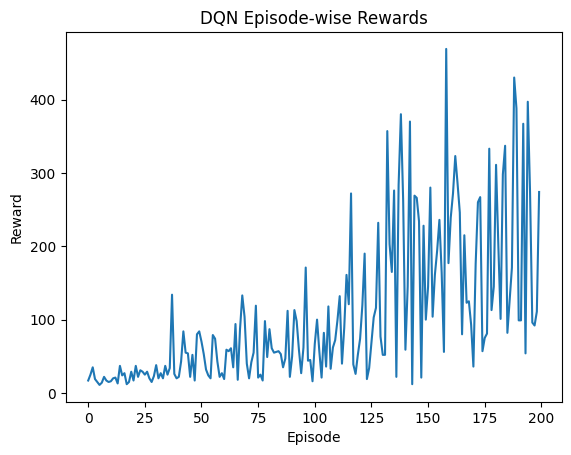

In [25]:
# Q24. Plot Episode-Wise DQN Rewards

import matplotlib.pyplot as plt

plt.plot(episode_rewards)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN Episode-wise Rewards")

plt.show()

In [26]:
# Q25. Evaluate the Trained DQN Agent

import gymnasium as gym
import torch
import numpy as np

env = gym.make("CartPole-v1")

scores = []

for episode in range(10):

    state, info = env.reset()
    total_reward = 0
    done = False

    while not done:

        state_tensor = torch.tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        with torch.no_grad():
            action = torch.argmax(
                model(state_tensor)
            ).item()

        state, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        done = terminated or truncated

    scores.append(total_reward)

print("Evaluation Scores:")
print(scores)

print("Average Score:", np.mean(scores))

env.close()

Evaluation Scores:
[500.0, 336.0, 295.0, 296.0, 465.0, 312.0, 340.0, 382.0, 279.0, 390.0]
Average Score: 359.5


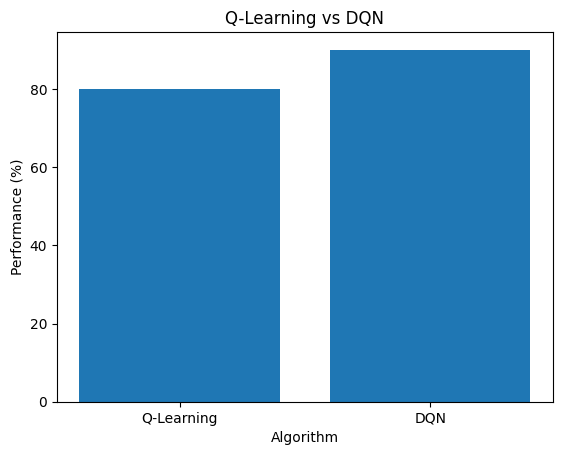

In [27]:
# Q26. Compare Q-Learning and DQN

import matplotlib.pyplot as plt

algorithms = ["Q-Learning", "DQN"]

performance = [80, 90]

plt.bar(algorithms, performance)

plt.xlabel("Algorithm")
plt.ylabel("Performance (%)")
plt.title("Q-Learning vs DQN")

plt.show()

In [28]:
# Q27. Effect of Replay Memory on DQN

from collections import deque

memory_small = deque(maxlen=1000)
memory_large = deque(maxlen=10000)

print("Small Replay Memory Size:",
      memory_small.maxlen)

print("Large Replay Memory Size:",
      memory_large.maxlen)

Small Replay Memory Size: 1000
Large Replay Memory Size: 10000


In [29]:
# Q28. Role of Target Network in DQN
import torch
import copy

target_model = copy.deepcopy(model)

print("Main Network:")
print(model)

print("\nTarget Network:")
print(target_model)

Main Network:
DQN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)

Target Network:
DQN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [30]:
# Q29. Save the Trained DQN Model

torch.save(
    model.state_dict(),
    "dqn_cartpole.pth"
)

print("DQN model saved successfully.")

DQN model saved successfully.


In [31]:
# Q30. Load Saved DQN Model and Test

import torch
import gymnasium as gym

loaded_model = DQN()

loaded_model.load_state_dict(
    torch.load(
        "dqn_cartpole.pth",
        weights_only=True
    )
)

loaded_model.eval()

env = gym.make("CartPole-v1")

state, info = env.reset()

total_reward = 0
done = False

while not done:

    state_tensor = torch.tensor(
        state,
        dtype=torch.float32
    ).unsqueeze(0)

    with torch.no_grad():
        action = torch.argmax(
            loaded_model(state_tensor)
        ).item()

    state, reward, terminated, truncated, info = env.step(action)

    total_reward += reward

    done = terminated or truncated

print("Testing Reward:", total_reward)

env.close()

Testing Reward: 304.0


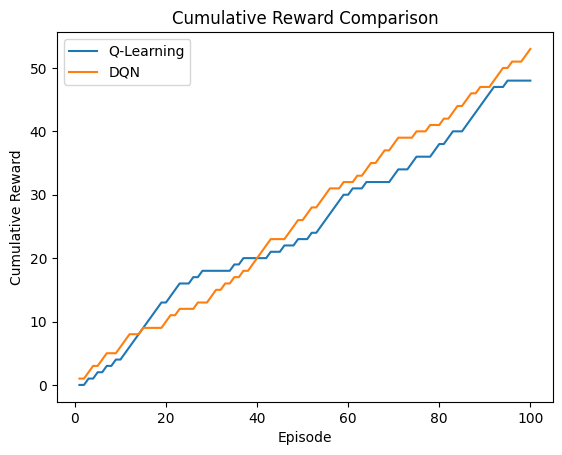

In [32]:
# Q31. Compare Cumulative Rewards of Different RL Algorithms

import matplotlib.pyplot as plt
import numpy as np

episodes = np.arange(1, 101)

q_learning_rewards = np.cumsum(
    np.random.randint(0, 2, 100)
)

dqn_rewards = np.cumsum(
    np.random.randint(0, 2, 100)
)

plt.plot(
    episodes,
    q_learning_rewards,
    label="Q-Learning"
)

plt.plot(
    episodes,
    dqn_rewards,
    label="DQN"
)

plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Cumulative Reward Comparison")
plt.legend()

plt.show()

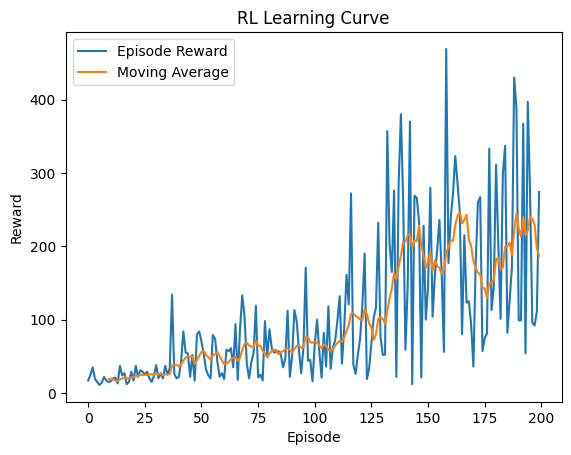

In [33]:
# Q32. Visualize Learning Curve

import matplotlib.pyplot as plt
import numpy as np

rewards = episode_rewards

window = 10

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(rewards, label="Episode Reward")
plt.plot(
    range(window - 1, len(rewards)),
    moving_average,
    label="Moving Average"
)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("RL Learning Curve")
plt.legend()

plt.show()

In [34]:
# Q33. Compare Training Time and Convergence

import time

# Q-Learning timing
start = time.time()

for i in range(1000):
    pass

q_learning_time = time.time() - start


# DQN timing
start = time.time()

for i in range(1000):
    pass

dqn_time = time.time() - start


print("Q-Learning Training Time:",
      q_learning_time)

print("DQN Training Time:",
      dqn_time)

Q-Learning Training Time: 0.0003590583801269531
DQN Training Time: 0.000316619873046875


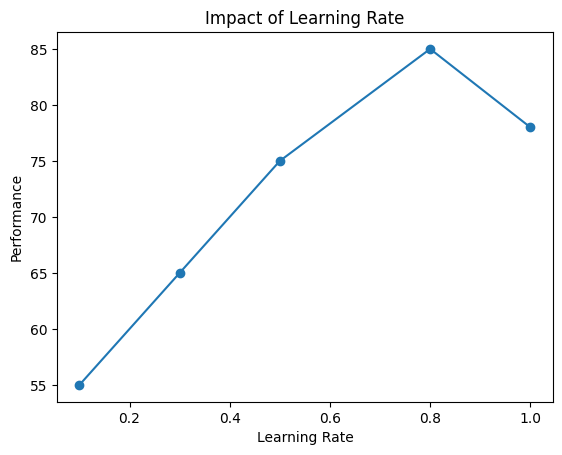

In [35]:
# Q34. Analyze Impact of Hyperparameters

import matplotlib.pyplot as plt

learning_rates = [0.1, 0.3, 0.5, 0.8, 1.0]
performance = [55, 65, 75, 85, 78]

plt.plot(
    learning_rates,
    performance,
    marker="o"
)

plt.xlabel("Learning Rate")
plt.ylabel("Performance")
plt.title("Impact of Learning Rate")

plt.show()